# Task 2: Technical Analysis with TA-Lib

Quantitative stock analysis using moving averages, RSI, and MACD.

In [3]:
import talib
import yfinance as yf
import pandas as pd

TICKER = "AAPL"

raw = yf.download(TICKER, start="2024-01-01", end="2024-05-01", progress=False)
raw.columns = raw.columns.get_level_values(0)
data = raw.reset_index()

close = data["Close"].astype(float)
data["SMA_10"] = talib.SMA(close, timeperiod=10)
data["EMA_10"] = talib.EMA(close, timeperiod=10)
data["RSI"] = talib.RSI(close, timeperiod=14)
data["MACD"], data["MACD_signal"], data["MACD_hist"] = talib.MACD(close)

data.head()


Price,Date,Close,High,Low,Open,Volume,SMA_10,EMA_10,RSI,MACD,MACD_signal,MACD_hist
0,2024-01-02,183.562195,186.330858,181.831782,185.055288,82488700,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-01-03,182.187775,183.799536,181.376945,182.158112,58414500,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-01-04,179.873947,181.040733,178.855477,180.111251,71983600,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-01-05,179.152100,180.714417,178.153410,179.953046,62379700,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-01-08,183.483093,183.522654,179.468538,180.051930,59144500,NaN,NaN,NaN,NaN,NaN,NaN


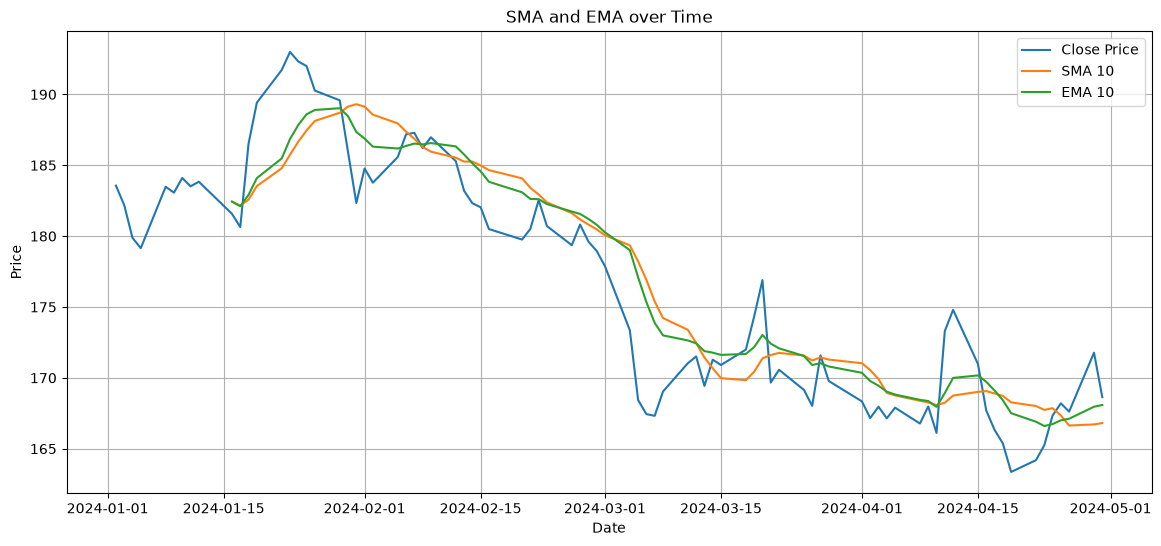

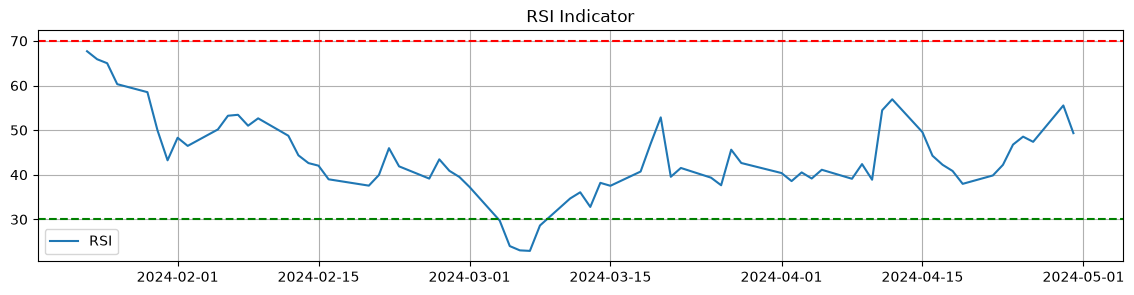

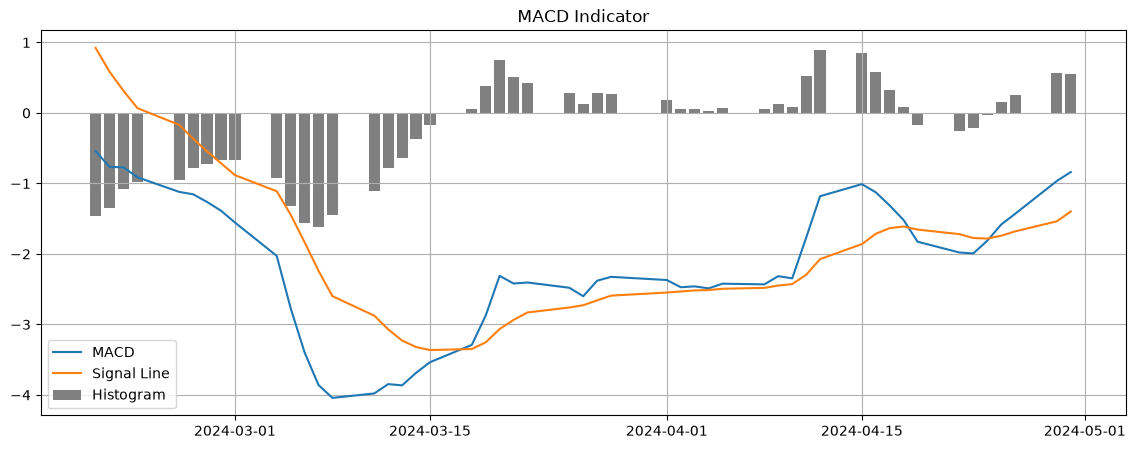

In [4]:
import matplotlib.pyplot as plt

# Plot SMA vs Price
plt.figure(figsize=(14, 6))
plt.plot(data['Date'], data['Close'], label='Close Price')
plt.plot(data['Date'], data['SMA_10'], label='SMA 10')
plt.plot(data['Date'], data['EMA_10'], label='EMA 10')
plt.title("SMA and EMA over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()

# Plot RSI
plt.figure(figsize=(14, 3))
plt.plot(data['Date'], data['RSI'], label='RSI')
plt.axhline(70, color='r', linestyle='--')  # Overbought
plt.axhline(30, color='g', linestyle='--')  # Oversold
plt.title("RSI Indicator")
plt.legend()
plt.grid(True)
plt.show()

# Plot MACD
plt.figure(figsize=(14, 5))
plt.plot(data['Date'], data['MACD'], label='MACD')
plt.plot(data['Date'], data['MACD_signal'], label='Signal Line')
plt.bar(data['Date'], data['MACD_hist'], label='Histogram', color='grey')
plt.title("MACD Indicator")
plt.legend()
plt.grid(True)
plt.show()
